# 5. Vanishing gradient

In the backward pass the gradient is multiplied, layer after layer, by the derivative of the activation
and by the weights. The derivative of the sigmoid is at most 0.25, so with small weights the gradient shrinks
at every layer. In a deep network almost nothing reaches the first layers and they do not learn.

We train two networks with **the same depth** (6 hidden layers of 32 units) on MNIST, with the same optimizer (SGD):

1. **Sigmoid + small normal initialization**: provokes the vanishing gradient;
2. **ReLU + He initialization**: the healthy reference.

To keep it fast we use 10,000 training images and 2,000 validation images.

In [1]:
import sys
sys.path.append("..")  # so we can import the code in src/

import numpy as np

from src.datasets import load_mnist
from src.nn import MLP
from src.optim import SGD
from src.training import train
from src.plots import plot_loss, plot_metric, plot_histograms, plot_gradient_sizes

PLOTS = "../assets/plots/"

In [2]:
X_train, y_train, X_val, y_val = load_mnist()

X_train = X_train[:10000]
y_train = y_train[:10000]
X_val = X_val[:2000]
y_val = y_val[:2000]

## Network 1: sigmoid + normal initialization (std = 0.1)

In [3]:
vanishing_model = MLP(input_size=784, hidden_sizes=[32, 32, 32, 32, 32, 32], output_size=10,
                      hidden_activation="sigmoid", output_activation="sigmoid",
                      init="normal", init_scale=0.1)

optimizer = SGD(vanishing_model.parameters(), lr=0.1)

vanishing_history = train(vanishing_model, optimizer, "bce", X_train, y_train, X_val, y_val,
                          epochs=10, batch_size=32, metric_name="accuracy", print_every=1)

epoch    1 | train loss 0.3250 | val loss 0.3250 | train accuracy 0.1127 | val accuracy 0.1170
epoch    2 | train loss 0.3249 | val loss 0.3249 | train accuracy 0.1127 | val accuracy 0.1170


epoch    3 | train loss 0.3249 | val loss 0.3250 | train accuracy 0.1070 | val accuracy 0.1025
epoch    4 | train loss 0.3249 | val loss 0.3250 | train accuracy 0.1127 | val accuracy 0.1170


epoch    5 | train loss 0.3248 | val loss 0.3250 | train accuracy 0.1127 | val accuracy 0.1170
epoch    6 | train loss 0.3249 | val loss 0.3250 | train accuracy 0.1127 | val accuracy 0.1170


epoch    7 | train loss 0.3249 | val loss 0.3249 | train accuracy 0.1127 | val accuracy 0.1170
epoch    8 | train loss 0.3249 | val loss 0.3249 | train accuracy 0.1127 | val accuracy 0.1170


epoch    9 | train loss 0.3249 | val loss 0.3249 | train accuracy 0.1127 | val accuracy 0.1170
epoch   10 | train loss 0.3248 | val loss 0.3249 | train accuracy 0.1127 | val accuracy 0.1170


The loss does not move and the accuracy stays at chance level (about 11%): the network is not learning.

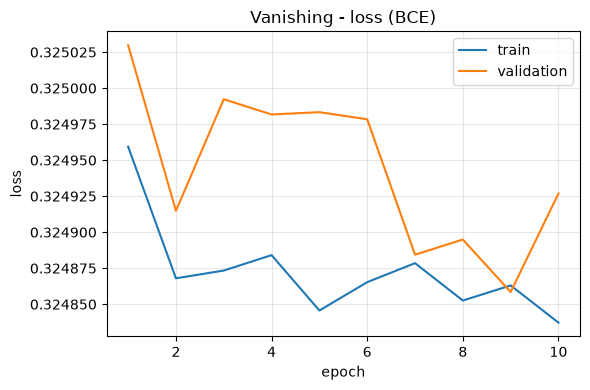

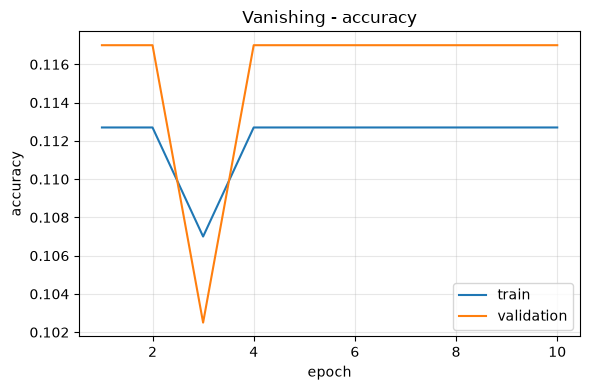

In [4]:
plot_loss(vanishing_history, title="Vanishing - loss (BCE)", save_path=PLOTS + "vanishing_loss.png")
plot_metric(vanishing_history, "accuracy", title="Vanishing - accuracy", save_path=PLOTS + "vanishing_accuracy.png")

The histograms show why. Look at the scale of the x axis of the gradients: it gets several orders of magnitude
smaller as we go from the last layer (right) to the first layer (left).

In the activations, the histograms of the deeper layers turn into a few isolated spikes around 0.5: each unit outputs
almost the same value for every image, so the information about the input is lost. They also do not change from epoch 1 to epoch 10.

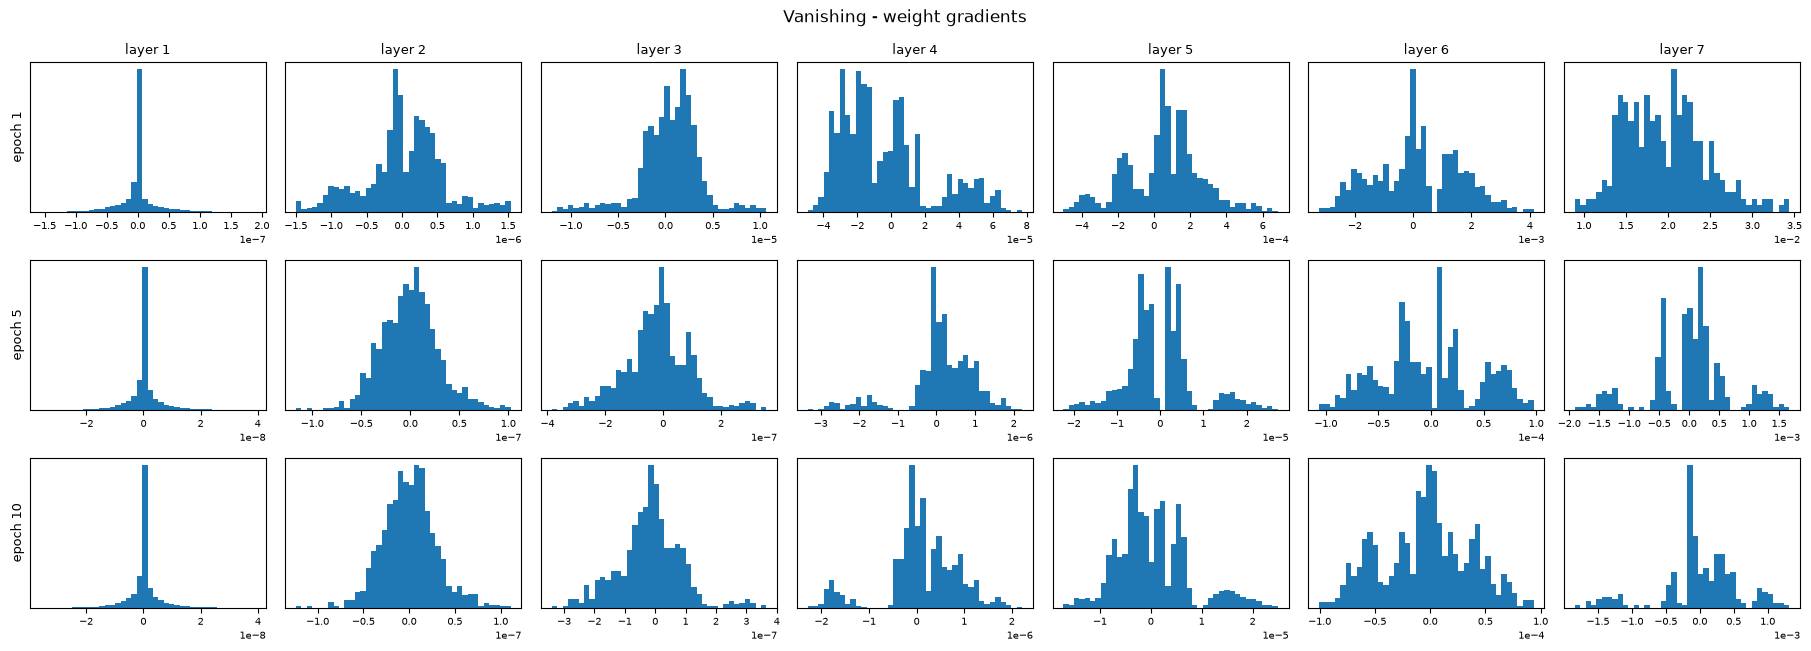

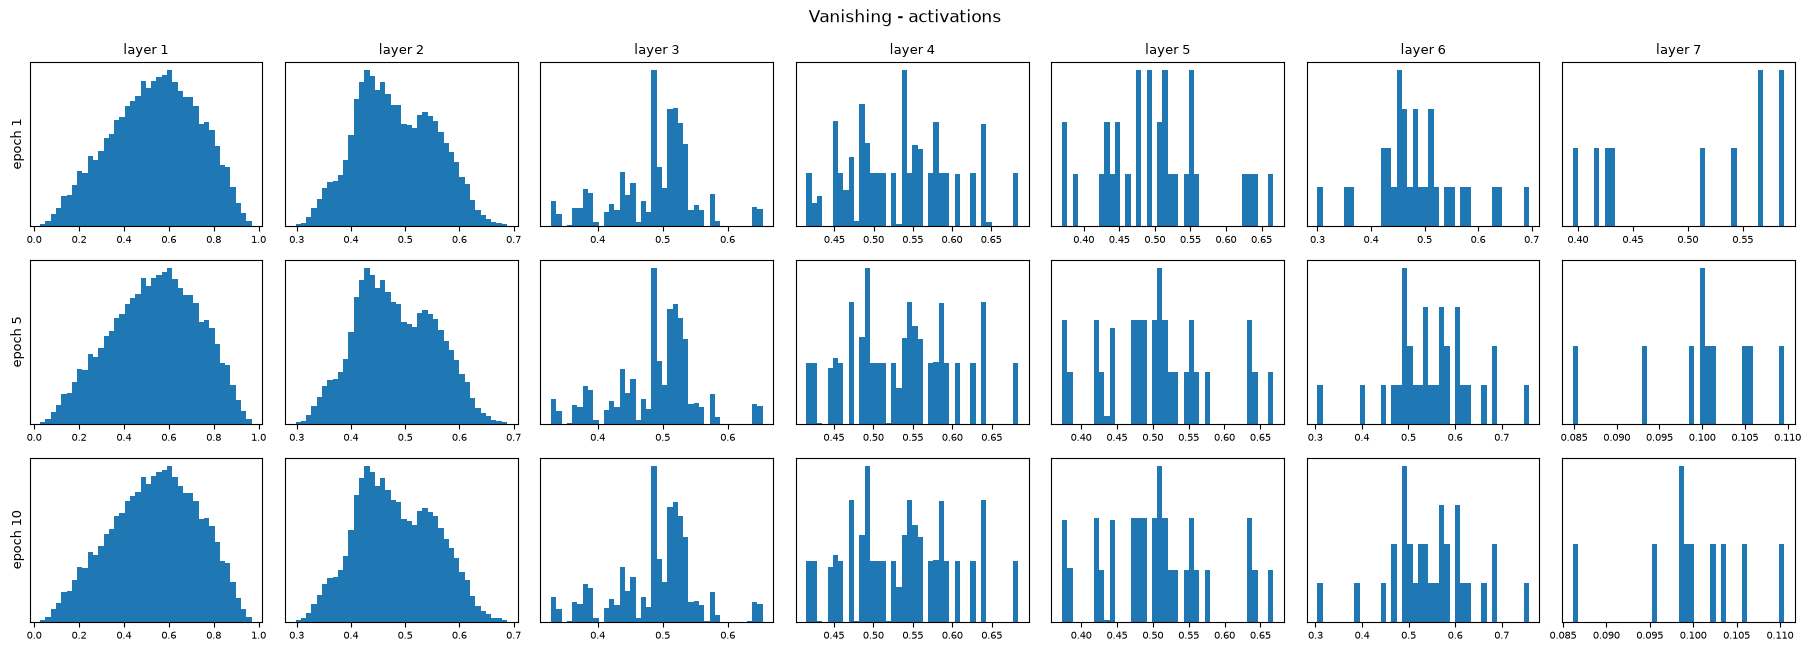

In [5]:
plot_histograms(vanishing_history, "gradients", title="Vanishing - weight gradients", save_path=PLOTS + "vanishing_gradients.png")
plot_histograms(vanishing_history, "activations", title="Vanishing - activations", save_path=PLOTS + "vanishing_activations.png")

## Network 2: ReLU + He initialization

In [6]:
healthy_model = MLP(input_size=784, hidden_sizes=[32, 32, 32, 32, 32, 32], output_size=10,
                    hidden_activation="relu", output_activation="sigmoid", init="he")

optimizer = SGD(healthy_model.parameters(), lr=0.1)

healthy_history = train(healthy_model, optimizer, "bce", X_train, y_train, X_val, y_val,
                        epochs=10, batch_size=32, metric_name="accuracy", print_every=1)

epoch    1 | train loss 0.1438 | val loss 0.1605 | train accuracy 0.7516 | val accuracy 0.7165
epoch    2 | train loss 0.1006 | val loss 0.1227 | train accuracy 0.8337 | val accuracy 0.7955


epoch    3 | train loss 0.0815 | val loss 0.1061 | train accuracy 0.8821 | val accuracy 0.8430
epoch    4 | train loss 0.0598 | val loss 0.0840 | train accuracy 0.9073 | val accuracy 0.8665


epoch    5 | train loss 0.0507 | val loss 0.0772 | train accuracy 0.9248 | val accuracy 0.8790
epoch    6 | train loss 0.0598 | val loss 0.0833 | train accuracy 0.9048 | val accuracy 0.8635


epoch    7 | train loss 0.0618 | val loss 0.0906 | train accuracy 0.8985 | val accuracy 0.8475
epoch    8 | train loss 0.0416 | val loss 0.0760 | train accuracy 0.9357 | val accuracy 0.8755


epoch    9 | train loss 0.0325 | val loss 0.0615 | train accuracy 0.9525 | val accuracy 0.9035
epoch   10 | train loss 0.0386 | val loss 0.0725 | train accuracy 0.9411 | val accuracy 0.8795


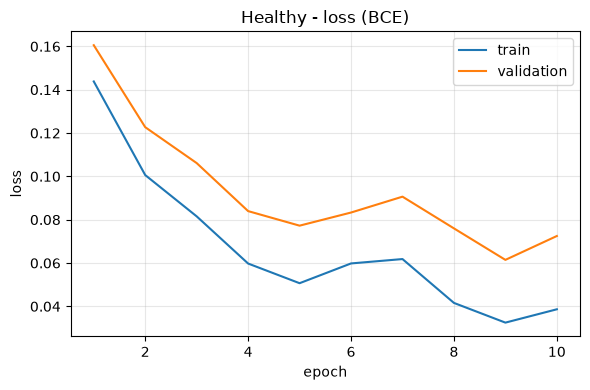

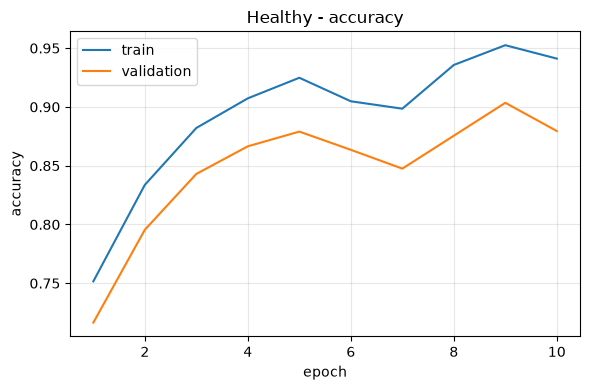

In [7]:
plot_loss(healthy_history, title="Healthy - loss (BCE)", save_path=PLOTS + "healthy_loss.png")
plot_metric(healthy_history, "accuracy", title="Healthy - accuracy", save_path=PLOTS + "healthy_accuracy.png")

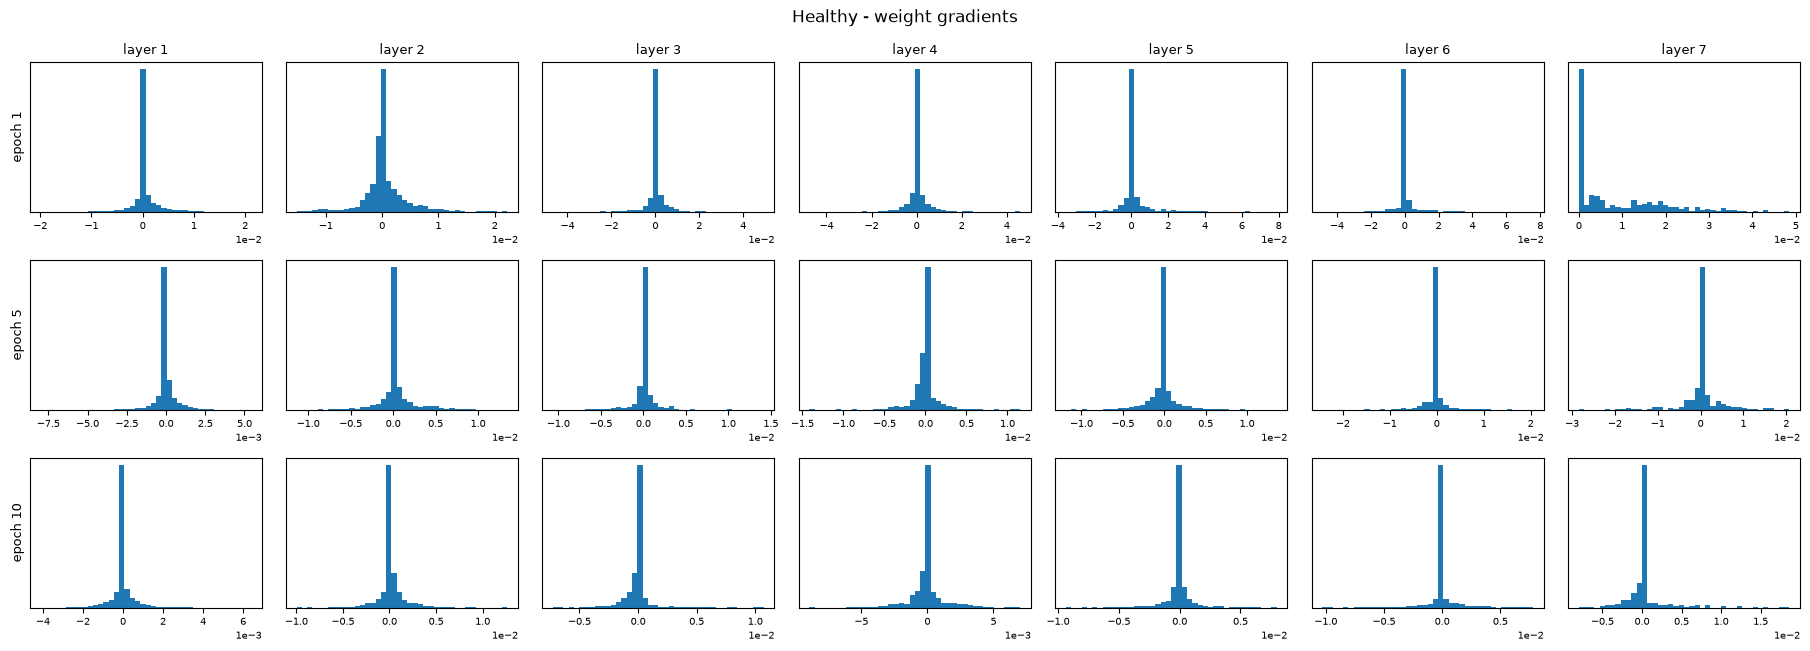

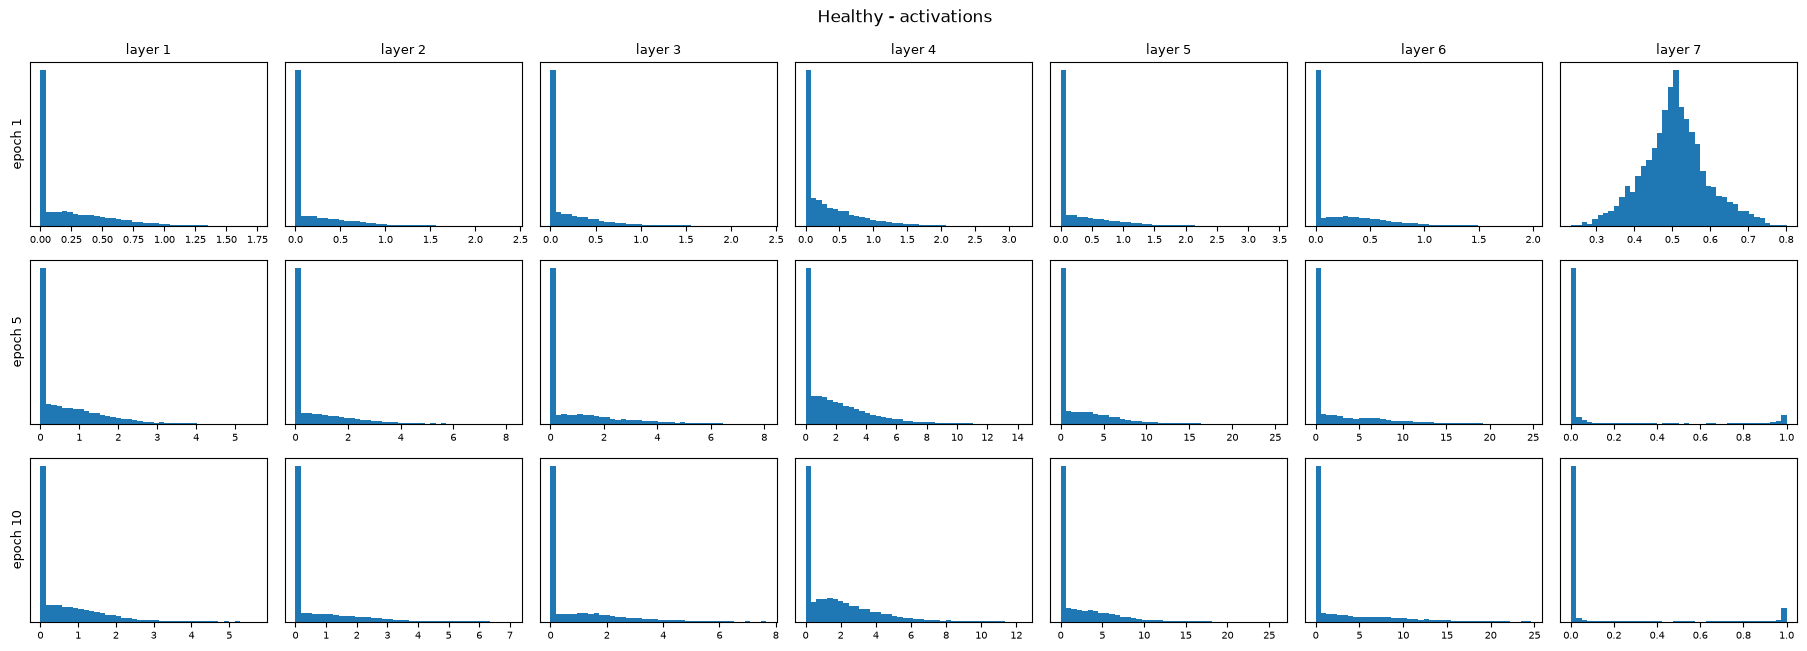

In [8]:
plot_histograms(healthy_history, "gradients", title="Healthy - weight gradients", save_path=PLOTS + "healthy_gradients.png")
plot_histograms(healthy_history, "activations", title="Healthy - activations", save_path=PLOTS + "healthy_activations.png")

## Side by side: gradient size per layer

Mean absolute value of the weight gradients of each layer, in log scale.
In the sigmoid network the gradient drops by roughly a factor of 10 at every layer going towards the input.
In the ReLU + He network all layers receive gradients of similar size.

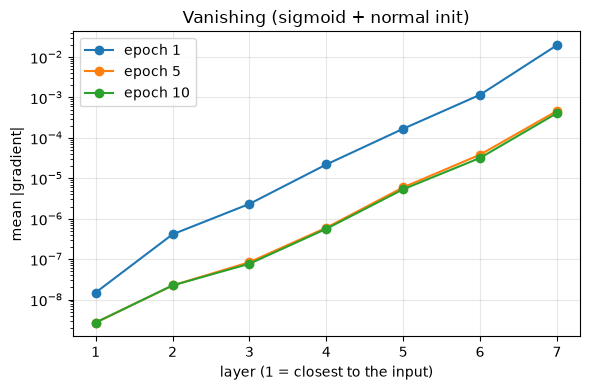

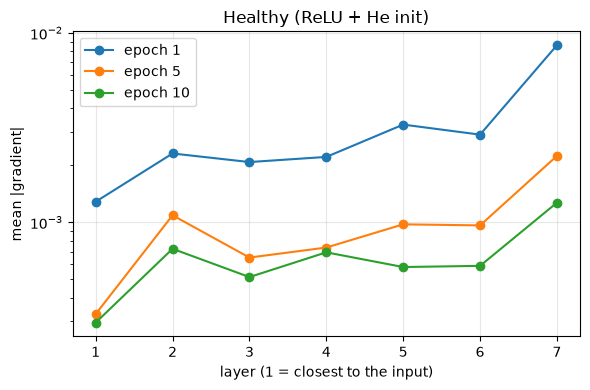

In [9]:
plot_gradient_sizes(vanishing_history, title="Vanishing (sigmoid + normal init)", save_path=PLOTS + "vanishing_gradient_sizes.png")
plot_gradient_sizes(healthy_history, title="Healthy (ReLU + He init)", save_path=PLOTS + "healthy_gradient_sizes.png")